This notebook is based on a follow-along of the Karpathy "Zero to Hero" on micrograd, which is a manual implementation of backpropagation for a neural net https://www.youtube.com/watch?v=VMj-3S1tku0

> Micrograd is an autograd (automatic gradient) engine which implements backpropogation. -> iteritavely tune weights wrt the neural net, to minimize the loss function.

Backpropagation works by applying the chain rule iteratively. In an expression like $$\frac{dL}{db} = \frac{de}{db} \cdot \frac{dd}{de} \cdot \frac{dL}{dd}$$we are essentially asking, for a small change in $b$, how does $L$ change? If $b$ is further upstream, more changes in the other nodes will have a downstream effect. Computing the analytical derivative may not be feasible, so we consider a numerical derivative, $$\frac{dL}{db}=\lim_{h \to \infty}\frac{L(b+h)-L(b)}{h}$$
> It’s just a recursive application of the chain rule

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

In [2]:
def f(x):
    return 3*x**2 - 4*x + 5

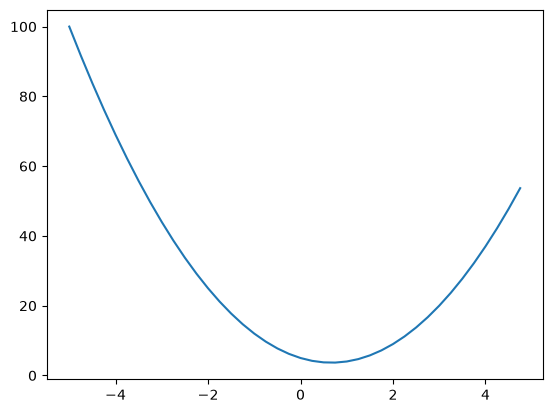

In [3]:
xs = np.arange(-5,5,0.25)
ys = f(xs)
plt.plot(xs, ys)

I followed the tutorial, which used "children", but I find it less confusing to think of them as "parents" instead.

In [48]:
class Value:
    def __init__(self, data, _children=(), _op="", label=""):
        self.data = data
        self.grad = 0.0
        self._backward = lambda: None
        self._prev = set(_children)
        self._op = _op
        self.label = label

    def __repr__(self):
        return f"Value(data={self.data})"

    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data + other.data, (self, other), "+")
        
        def _backward():
            self.grad += 1.0 * out.grad
            other.grad += 1.0 * out.grad
        out._backward = _backward
        
        return out

    def __mul__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data * other.data, (self, other), "*")
        
        def _backward():
            self.grad += other.data * out.grad
            other.grad += self.data * out.grad
        out._backward = _backward
        
        return out

    def __rmul__(self, other):
        # other * self
        return self * other
    
    def __neg__(self):
        return self * -1

    def __sub__(self, other):
        return self + (-other)

    def __truediv__(self, other):
        return self * (other**-1)

    def __pow__(self, other):
        assert isinstance(other, (int, float)), "only supporting int/float powers"
        out = Value(self.data**other, (self,), f"**{other}")

        def _backward():
            self.grad += other * (self.data ** (other-1)) * out.grad
        out._backward = _backward

        return out

    def tanh(self):
        
        n = self.data
        t = (math.exp(2*n) - 1) / (math.exp(2*n) + 1)
        out = Value(t, (self, ), "tanh")

        def _backward():
            self.grad += (1 - t ** 2) * out.grad
        out._backward = _backward
        
        return out

    def exp(self):
        x = self.data
        out = Value(math.exp(x), (self,), "exp")

        def _backward():
            self.grad += out.grad * out.data
        out._backward = _backward

        return out
    
    def backward(self):

        topo = []
        visited = set()
        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                topo.append(v)
        build_topo(self)

        self.grad = 1.0
        for node in reversed(topo):
            node._backward()

In [49]:
a = Value(2)
b = Value(4)
y = a / b
y

Value(data=0.5)

In [22]:
a = Value(2, label="a")
b = Value(-3, label="b")
c = Value(10, label="c")
e = a * b; e.label = "e"
d = e + c; d.label = "d"
f = Value(-2.0, label="f")
L = d*f; L.label= "L"
L

Value(data=-8.0)

In [5]:
# For visualizing the graphs
# I've just copied this without trying to understand it
from graphviz import Digraph

def trace(root):
    nodes, edges = set(), set()
    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child, v))
                build(child)
    build(root)
    return nodes, edges

def draw_dot(root):
    dot = Digraph(format="svg", graph_attr={"rankdir" : "LR"})

    nodes, edges = trace(root)
    for n in nodes:
        uid =str(id(n))
        dot.node(name = uid, label = "{ %s | data %.4f | grad %.4f}" % (n.label, n.data, n.grad), shape="record")
        if n._op:
            dot.node(name = uid + n._op, label = n._op)
            dot.edge(uid + n._op, uid)

    for n1, n2 in edges:
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)

    return dot

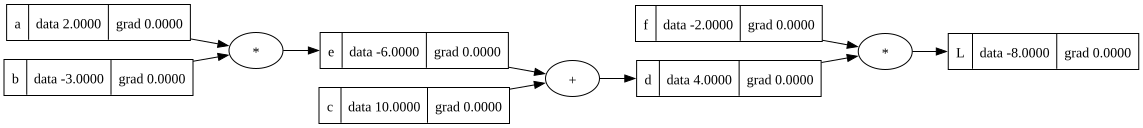

In [6]:
draw_dot(L)

In [7]:
# Manually set L grad
L.grad = 1.0
f.grad = 4.0 
d.grad = -2.0 
c.grad = -2.0
e.grad = -2.0
b.grad = -4.0 
a.grad = 6.0

$$\frac{dL}{db} = \frac{de}{db} \cdot \frac{dd}{de} \cdot \frac{dL}{dd}$$

In [8]:
def lol():
    a = Value(2, label="a")
    b = Value(-3, label="b")
    c = Value(10, label="c")
    e = a * b; e.label = "e"
    d = e + c; d.label = "d"
    f = Value(-2.0, label="f")
    L = d*f; L.label= "L"
    L1 = L.data

    h = 0.00001
    a = Value(2, label="a")
    b = Value(-3, label="b")
    b.data += h
    c = Value(10, label="c")
    e = a * b; e.label = "e"
    d = e + c; d.label = "d"
    f = Value(-2.0, label="f")
    L = d*f; L.label= "L"
    L2 = L.data

    print((L2-L1)/h)

lol()

-4.000000000026205


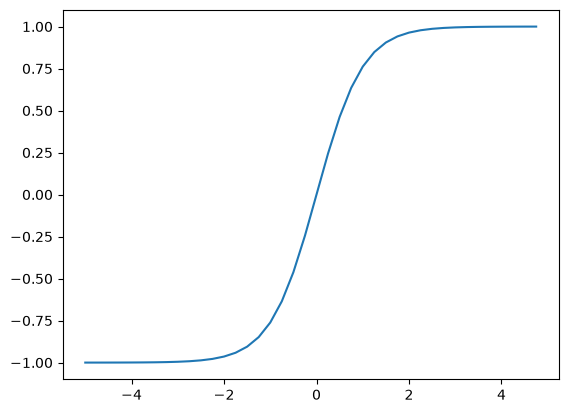

In [9]:
# tanh as an activation function
plt.plot(xs,np.tanh(xs))

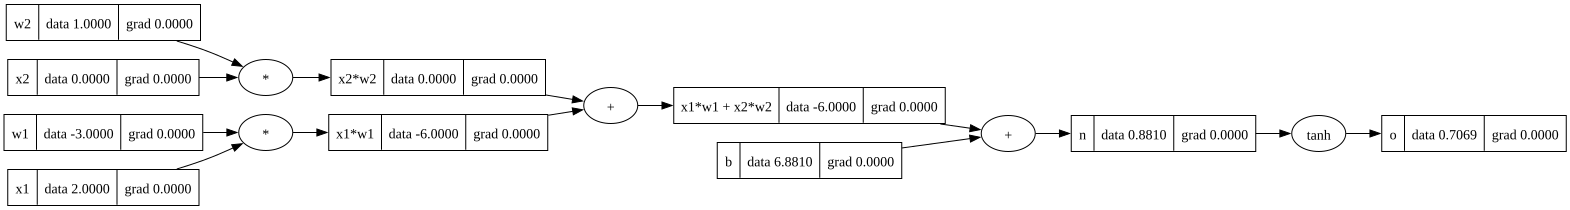

In [10]:
# inputs x1, x2 
x1 = Value(2.0, label="x1")
x2 = Value(0.0, label="x2")
# weights of the neuron
w1 = Value(-3.0, label="w1")
w2 = Value(1.0, label="w2")
# bias of the neuron 
b = Value(6.881, label="b")


x1w1 = x1*w1; x1w1.label= "x1*w1"
x2w2 = x2*w2; x2w2.label= "x2*w2"
x1w1x2w2 = x1w1 + x2w2 ; x1w1x2w2.label= "x1*w1 + x2*w2"

n = x1w1x2w2 + b; n.label = "n"
o = n.tanh() ; o.label = "o"
draw_dot(o)

$$\frac{d}{dx} \tanh(x) = 1 - \tanh ^2 (x)$$
so,
$$\frac{do}{dn} = 1 - (\tanh(o))^2$$

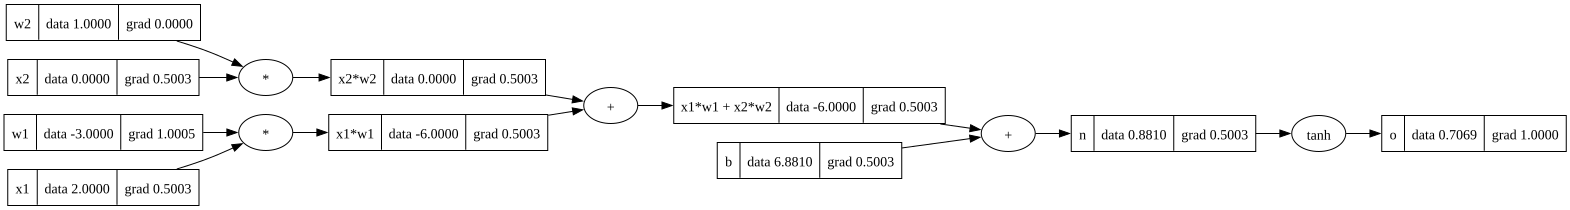

In [11]:
# Manually fill in the gradients
o.grad = 1
n.grad = 1 - o.data ** 2
x1w1x2w2.grad = n.grad
b.grad = n.grad
x1w1.grad = x1w1x2w2.grad
x2w2.grad = x1w1x2w2.grad
w1.grad = x1.data * x1w1.grad
x1.grad = w2.data * x1w1.grad
w2.grad = x2.data * x2w2.grad
x2.grad = w2.data * x2w2.grad
draw_dot(o)

#### Make the backward pass automatic

In [12]:
# inputs x1, x2 
x1 = Value(2.0, label="x1")
x2 = Value(0.0, label="x2")
# weights of the neuron
w1 = Value(-3.0, label="w1")
w2 = Value(1.0, label="w2")
# bias of the neuron 
b = Value(6.881, label="b")


x1w1 = x1*w1; x1w1.label= "x1*w1"
x2w2 = x2*w2; x2w2.label= "x2*w2"
x1w1x2w2 = x1w1 + x2w2 ; x1w1x2w2.label= "x1*w1 + x2*w2"

n = x1w1x2w2 + b; n.label = "n"
o = n.tanh() ; o.label = "o"

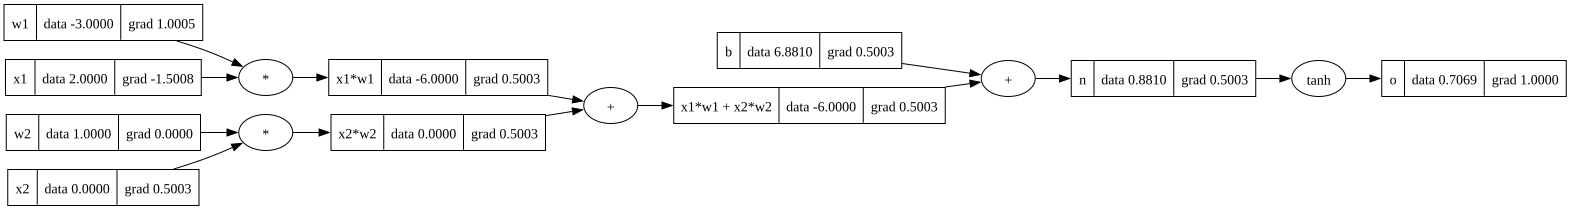

In [13]:
# Set the base case first
# Then step by step backpropagation
o.grad = 1.0
o._backward()
n._backward()
x1w1x2w2._backward()
x1w1._backward()
x2w2._backward()

draw_dot(o)

Use topological sort to ensure all the downstream backpropagations are already computed, before determining the gradient. Then the backpropagation can be down in one go. 

In [14]:
# Copied topological sort
# This is a linear ordering of the verticies#
# (Move to inside of the Value class)
topo = []
visited = set()
def build_topo(v):
    if v not in visited:
        visited.add(v)
        for child in v._prev:
            build_topo(child)
        topo.append(v)
build_topo(o)

o.grad = 1.0
for node in reversed(topo):
    node._backward()


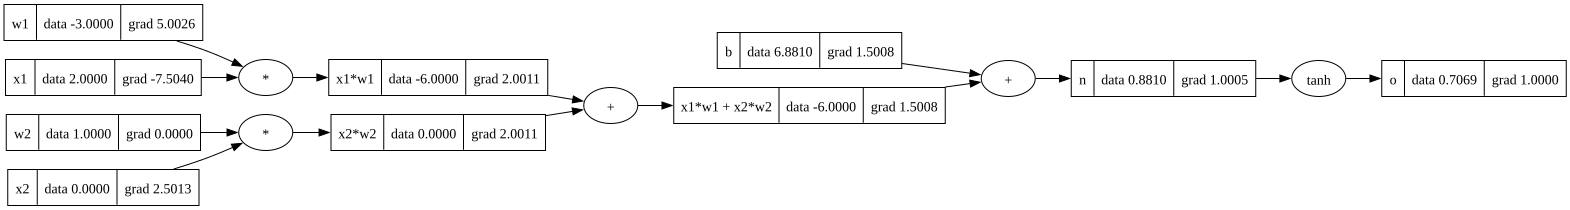

In [15]:
draw_dot(o)

In [20]:
# inputs x1, x2 
x1 = Value(2.0, label="x1")
x2 = Value(0.0, label="x2")
# weights of the neuron
w1 = Value(-3.0, label="w1")
w2 = Value(1.0, label="w2")
# bias of the neuron 
b = Value(6.881, label="b")


x1w1 = x1*w1; x1w1.label= "x1*w1"
x2w2 = x2*w2; x2w2.label= "x2*w2"
x1w1x2w2 = x1w1 + x2w2 ; x1w1x2w2.label= "x1*w1 + x2*w2"

n = x1w1x2w2 + b; n.label = "n"
o = n.tanh() ; o.label = "o"

o.backward()

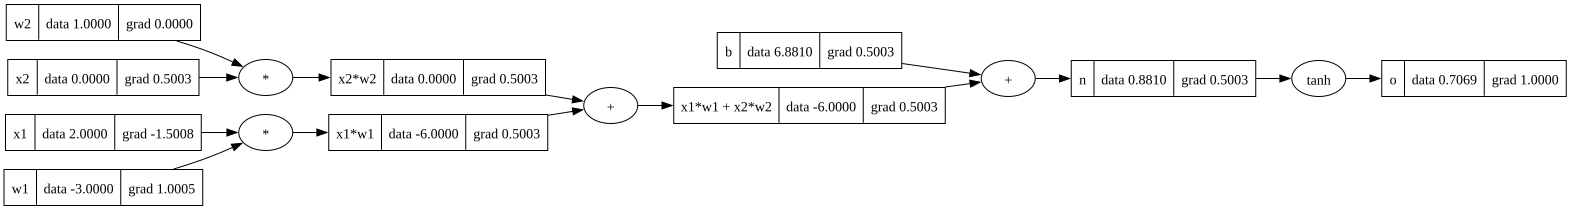

In [21]:
draw_dot(o)

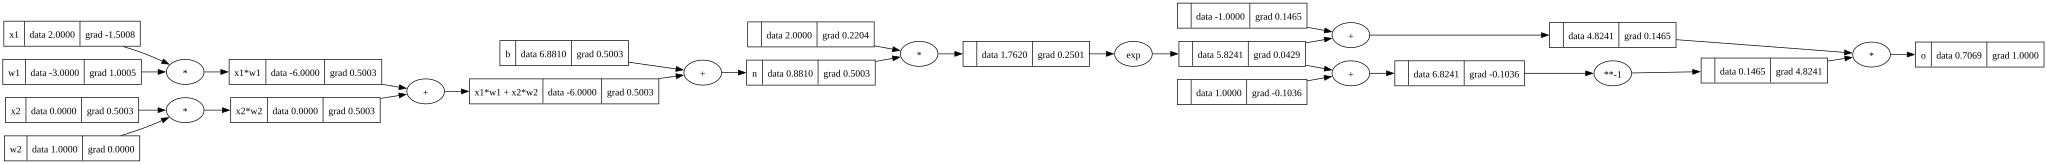

In [53]:
# Evaluate o without using tanh directly
# inputs x1, x2 
x1 = Value(2.0, label="x1")
x2 = Value(0.0, label="x2")
# weights of the neuron
w1 = Value(-3.0, label="w1")
w2 = Value(1.0, label="w2")
# bias of the neuron 
b = Value(6.881, label="b")


x1w1 = x1*w1; x1w1.label= "x1*w1"
x2w2 = x2*w2; x2w2.label= "x2*w2"
x1w1x2w2 = x1w1 + x2w2 ; x1w1x2w2.label= "x1*w1 + x2*w2"

n = x1w1x2w2 + b; n.label = "n"
# ---
e = (2 * n).exp()
o = (e - 1) / (e + 1) ; o.label = "o"
# ---

o.backward()
draw_dot(o)

In [55]:
# Implementing the same thing, but in pytorch
import torch

x1 = torch.Tensor([2.0]).double()           ; x1.requires_grad = True
x2 = torch.Tensor([0.0]).double()           ; x2.requires_grad = True
w1 = torch.Tensor([-3.0]).double()          ; w1.requires_grad = True
w2 = torch.Tensor([1.0]).double()           ; w2.requires_grad = True
b = torch.Tensor([6.88137]).double()
n = x1*w1 + x2*w2 + b
o = torch.tanh(n)

print(o.data.item())
o.backward()

print("--------")
print("x2", x2.grad.item())
print("w2", w2.grad.item())
print("x1", x1.grad.item())
print("w1", w1.grad.item())

0.7071050214706146
--------
x2 0.5000024886110417
w2 0.0
x1 -1.500007465833125
w1 1.0000049772220834
